# 🐻 FuelIQ — Pitch Asset Builder

**Press *Run All*.** This notebook re-runs the full FuelIQ research pipeline once, in the same order as the master technical report, and writes everything you need for the Blaise xTech one-page pitch into one zip:

```
fueliq_pitch_assets.zip
├── README.md          ← index: every figure/table, caption, and where to use it in the pitch
├── figures/           ← 300-dpi PNGs (fig01 … fig11), each carrying the research-proof-of-concept caveat
└── tables/            ← every table as .csv AND .md (paste-ready), t01 … t15
```

**What is preserved from the master report**
- Same splits (train 107 / validation 36 / test 36), same 1,901 Raman variables (400–2300 cm⁻¹), same preprocessing, same grid (140 configs), same frozen model (RBF-SVR, C = 10, ε = 0.01, γ = 0.0003).
- The official test set is touched **once**, only after the model is frozen, and is **not** used for applicability-domain thresholds.
- Table **t14** compares every number this run produces with the master report and flags any difference, so nothing wrong reaches the pitch.

**What is added (clearly labelled)**
- Bootstrap 95 % confidence intervals on the 36-sample test metrics (sampling uncertainty only).
- A three-tier Routine / Review / Lab summary of the cross-validated distances.

> **Caveat carried on every figure:** research proof of concept on a public 785 nm handheld Raman dataset — *not* native Blaise performance, *not* field- or regulatory-validated, thresholds exploratory.

Needs internet once (Hugging Face dataset download). Typical run time: about a minute or two.

In [1]:
# ==================================================================
# 🐻 FUELIQ — PITCH ASSET BUILDER · step 1/10 · setup, helpers, folders
# ==================================================================
import os, sys, math, shutil, subprocess, warnings, zipfile, platform
from datetime import datetime, timezone
warnings.filterwarnings("ignore")

try:
    import datasets  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "datasets"], check=True)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from scipy.signal import savgol_filter
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
from sklearn.svm import SVR
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import datasets as hf_datasets
from datasets import load_dataset

try:
    from IPython.display import display, Markdown, FileLink
except Exception:                                   # plain-python fallback
    def display(x): print(x)
    def Markdown(x): return x
    FileLink = None

# ---------------- configuration (matches the master report) ----------------
DATASET_ID = "HTW-KI-Werkstatt/FuelRamanSpectraHandheld"
TARGET     = "Research Octane Number"
WN_MIN, WN_MAX, N_RAMAN = 400.0, 2300.0, 1901
FROZEN     = dict(C=10.0, epsilon=0.01, gamma=0.0003)      # frozen before the test set
CV_SPLITS, CV_SEED = 5, 42
BOOT_N, BOOT_SEED  = 2000, 7

OUT_BASE  = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()
ASSET_DIR = os.path.join(OUT_BASE, "fueliq_pitch_assets")
FIG_DIR   = os.path.join(ASSET_DIR, "figures")
TAB_DIR   = os.path.join(ASSET_DIR, "tables")
ZIP_PATH  = os.path.join(OUT_BASE, "fueliq_pitch_assets.zip")
shutil.rmtree(ASSET_DIR, ignore_errors=True)               # fresh output every run
os.makedirs(FIG_DIR); os.makedirs(TAB_DIR)

CAVEAT_FOOTER = ("Research proof of concept · public 785 nm handheld Raman dataset (179 gasoline samples) · "
                 "not native Blaise data · not field-validated")
PALETTE = dict(train="#4c78a8", val="#f2a541", test="#d1495b", ink="#10222b", grey="#6b7780",
               routine="#2a9d6f", review="#e9a23b", lab="#d1495b", accent="#2846ff")
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.18, "figure.dpi": 110,
                     "axes.titleweight": "bold", "axes.titlesize": 11})

FIGS, TABS = [], []          # registries → README index

# ---------------- helpers ----------------
def vector_normalize(X):
    n = np.linalg.norm(X, axis=1, keepdims=True)
    n[n == 0] = 1.0
    return X / n

def metrics(y_true, pred):
    y_true = np.asarray(y_true, float); pred = np.asarray(pred, float).reshape(-1)
    err = pred - y_true
    return {"R2": r2_score(y_true, pred),
            "MAE": mean_absolute_error(y_true, pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, pred))),
            "Bias": float(np.mean(err)),
            "W02": float(np.mean(np.abs(err) <= 0.2) * 100),
            "W07": float(np.mean(np.abs(err) <= 0.7) * 100)}

def _cell(v, d):
    if isinstance(v, (float, np.floating)):
        return "" if np.isnan(v) else f"{v:.{d}f}"
    if isinstance(v, (int, np.integer)):
        return str(int(v))
    return str(v).replace("|", "/")

def md_table(df, decimals=3):
    cols = list(df.columns)
    dec = decimals if isinstance(decimals, dict) else {}
    dflt = decimals if isinstance(decimals, int) else 3
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for row in df.itertuples(index=False):
        lines.append("| " + " | ".join(_cell(v, dec.get(c, dflt)) for c, v in zip(cols, row)) + " |")
    return "\n".join(lines)

def save_table(df, stem, title, note="", use="", decimals=3, md=True, show=True):
    df.to_csv(os.path.join(TAB_DIR, f"{stem}.csv"), index=False)
    if md:
        with open(os.path.join(TAB_DIR, f"{stem}.md"), "w", encoding="utf-8") as f:
            f.write(f"### {title}\n\n{md_table(df, decimals)}\n")
            if note: f.write(f"\n*{note}*\n")
    TABS.append(dict(stem=stem, title=title, note=note, use=use, rows=len(df), md=md))
    if show:
        display(Markdown(f"**{title}**"))
        display(df.head(20))
    return df

def save_figure(fig, stem, title, caption, use="", footer=True, footer_size=6.5):
    if footer:
        foot = CAVEAT_FOOTER if fig.get_figwidth() >= 7.4 else CAVEAT_FOOTER.replace(" · not native", "\nnot native", 1)
        fig.tight_layout(rect=(0, 0.04 if "\n" not in foot else 0.075, 1, 1))
        fig.text(0.5, 0.008, foot, ha="center", va="bottom", fontsize=footer_size, color=PALETTE["grey"], linespacing=1.3)
    else:
        fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, f"{stem}.png"), dpi=300, facecolor="white")
    plt.show(); plt.close(fig)
    FIGS.append(dict(stem=stem, title=title, caption=caption, use=use))

RUN_INFO = {"utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
            "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "datasets": hf_datasets.__version__}
print("=" * 70); print("🐻 FUELIQ — PITCH ASSET BUILDER"); print("=" * 70)
print("Output folder:", ASSET_DIR); print("Zip file     :", ZIP_PATH); print("Versions     :", RUN_INFO)

🐻 FUELIQ — PITCH ASSET BUILDER
Output folder: /kaggle/working/fueliq_pitch_assets
Zip file     : /kaggle/working/fueliq_pitch_assets.zip
Versions     : {'utc': '2026-10-11 20:20 UTC', 'python': '3.13.15', 'numpy': '2.1.3', 'pandas': '2.3.3', 'scikit-learn': '1.6.1', 'datasets': '4.8.5'}


## 2 · Load the public dataset and run integrity checks
Same dataset and official splits as the master report. The notebook stops with an error if the Raman variable count is not exactly **1,901**. Outputs: **t01** (dataset summary), **t02** (integrity checks), **fig01** (dataset overview), **fig02** (example spectra and where the octane signal sits — development set only).

README.md:   0%|          | 0.00/2.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B / 2.34MB            

train.parquet: downloading bytes:           |  0.00B            

val.parquet: reconstructing file:   0%|          |  0.00B / 1.62MB            

val.parquet: downloading bytes:           |  0.00B            

...

{'train': 107, 'validation': 36, 'test': 36}
✓ 1901 Raman variables, 400–2300 cm⁻¹ | dev=143 test=36


**Table 1 — Dataset summary (FuelRamanSpectraHandheld)**

,Split,Samples,RON min,RON max,RON mean,RON median,RON std
0,Training,107,89.4,104.8,97.704579,96.80,2.559673
1,Validation,36,95.3,102.3,97.804722,96.65,2.386529
2,Test (held out),36,95.1,102.2,97.886111,96.90,2.365484
3,Development (train + val),143,89.4,104.8,97.729790,96.76,2.509303
4,All samples,179,89.4,104.8,97.761229,96.80,2.475343


**Table 2 — Data integrity checks**

,Check,Result,Expected,Pass
0,Raman variables used (400–2300 cm⁻¹),1901,1901,PASS
1,Missing spectral values (all splits),0,0,PASS
2,Missing RON labels,0,0,PASS
3,Identical spectra shared across splits,0,0,PASS
4,Test samples used for tuning or thresholds,0,0,PASS


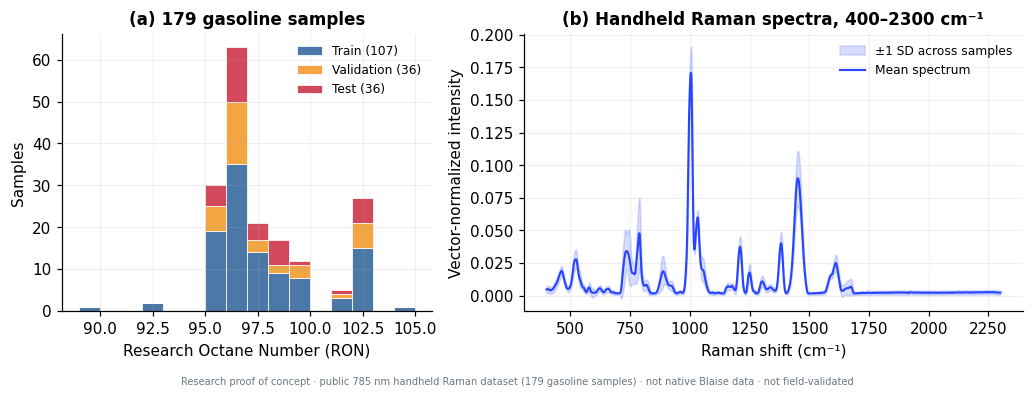

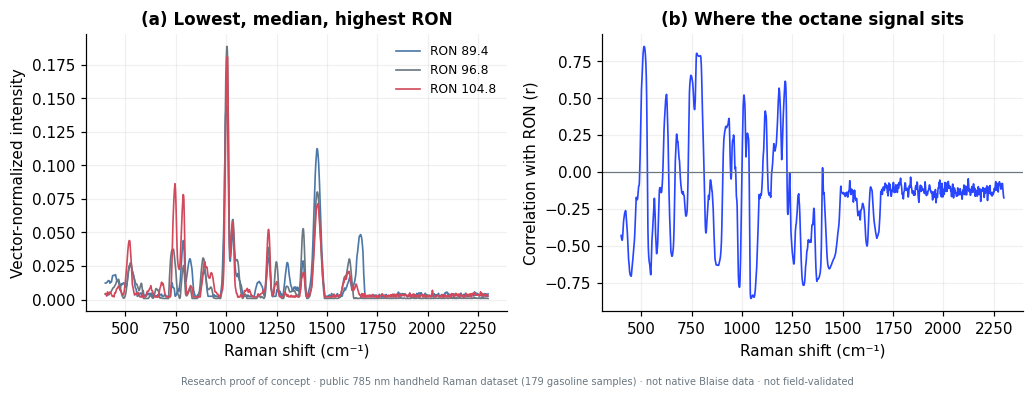

In [2]:
# ==================================================================
# step 2/10 · load data, integrity checks, dataset figures
# ==================================================================
ds = load_dataset(DATASET_ID)
train_df, val_df, test_df = ds["train"].to_pandas(), ds["validation"].to_pandas(), ds["test"].to_pandas()
print({k: ds[k].num_rows for k in ds})

raman_cols = []
for c in train_df.columns:
    try:
        wn = float(c)
        if WN_MIN <= wn <= WN_MAX and c in val_df.columns and c in test_df.columns:
            raman_cols.append(c)
    except (ValueError, TypeError):
        pass
raman_cols = sorted(raman_cols, key=float)
if len(raman_cols) != N_RAMAN:
    raise ValueError(f"Expected {N_RAMAN} Raman variables, found {len(raman_cols)} — STOP.")
wavenumbers = np.array([float(c) for c in raman_cols])

def spectra(df): return df[raman_cols].apply(pd.to_numeric, errors="coerce").values.astype(float)
def target(df):  return pd.to_numeric(df[TARGET], errors="coerce").values.astype(float)

X_train, X_val, X_test = spectra(train_df), spectra(val_df), spectra(test_df)
y_train, y_val, y_test = target(train_df), target(val_df), target(test_df)
X_dev, y_dev = np.vstack([X_train, X_val]), np.concatenate([y_train, y_val])
X_all, y_all = np.vstack([X_dev, X_test]), np.concatenate([y_dev, y_test])
print(f"✓ {len(raman_cols)} Raman variables, {wavenumbers[0]:.0f}–{wavenumbers[-1]:.0f} cm⁻¹ | dev={len(y_dev)} test={len(y_test)}")

# ---- t01 dataset summary ----
def ron_row(name, y):
    return {"Split": name, "Samples": len(y), "RON min": y.min(), "RON max": y.max(),
            "RON mean": y.mean(), "RON median": float(np.median(y)), "RON std": y.std(ddof=1)}
t01 = pd.DataFrame([ron_row("Training", y_train), ron_row("Validation", y_val), ron_row("Test (held out)", y_test),
                    ron_row("Development (train + val)", y_dev), ron_row("All samples", y_all)])
save_table(t01, "t01_dataset_summary", "Table 1 — Dataset summary (FuelRamanSpectraHandheld)",
           note="Public research dataset, 785 nm handheld Raman instrument. Splits are the dataset's predefined splits.",
           use="Pitch field 5 (data), supporting table", decimals={"RON min": 1, "RON max": 1, "RON mean": 2, "RON median": 1, "RON std": 2})

# ---- t02 integrity checks ----
def row_keys(X): return {hash(np.round(r, 6).tobytes()) for r in np.nan_to_num(X)}
k_tr, k_va, k_te = row_keys(X_train), row_keys(X_val), row_keys(X_test)
dups = len(k_tr & k_va) + len(k_tr & k_te) + len(k_va & k_te)
t02 = pd.DataFrame([
    {"Check": "Raman variables used (400–2300 cm⁻¹)", "Result": len(raman_cols), "Expected": N_RAMAN, "Pass": len(raman_cols) == N_RAMAN},
    {"Check": "Missing spectral values (all splits)", "Result": int(np.isnan(X_all).sum()), "Expected": 0, "Pass": int(np.isnan(X_all).sum()) == 0},
    {"Check": "Missing RON labels", "Result": int(np.isnan(y_all).sum()), "Expected": 0, "Pass": int(np.isnan(y_all).sum()) == 0},
    {"Check": "Identical spectra shared across splits", "Result": dups, "Expected": 0, "Pass": dups == 0},
    {"Check": "Test samples used for tuning or thresholds", "Result": 0, "Expected": 0, "Pass": True}])
t02["Pass"] = t02["Pass"].map({True: "PASS", False: "CHECK"})
save_table(t02, "t02_data_integrity_checks", "Table 2 — Data integrity checks",
           note="The last row is a design rule enforced by this notebook's structure: the test set is evaluated once, after the model is frozen.",
           use="Pitch field 5 (rigor), supporting table")

# ---- fig01 dataset overview ----
Xn_all = vector_normalize(np.nan_to_num(X_all))
mu, sd = Xn_all.mean(0), Xn_all.std(0)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6), gridspec_kw={"width_ratios": [1, 1.35]})
bins = np.arange(np.floor(y_all.min()), np.ceil(y_all.max()) + 1, 1.0)
ax[0].hist([y_train, y_val, y_test], bins=bins, stacked=True, edgecolor="white", linewidth=.5,
           color=[PALETTE["train"], PALETTE["val"], PALETTE["test"]],
           label=[f"Train ({len(y_train)})", f"Validation ({len(y_val)})", f"Test ({len(y_test)})"])
ax[0].set(xlabel="Research Octane Number (RON)", ylabel="Samples", title="(a) 179 gasoline samples"); ax[0].legend(frameon=False, fontsize=8)
ax[1].fill_between(wavenumbers, mu - sd, mu + sd, color=PALETTE["accent"], alpha=.18, label="±1 SD across samples")
ax[1].plot(wavenumbers, mu, color=PALETTE["accent"], lw=1.4, label="Mean spectrum")
ax[1].set(xlabel="Raman shift (cm⁻¹)", ylabel="Vector-normalized intensity", title="(b) Handheld Raman spectra, 400–2300 cm⁻¹"); ax[1].legend(frameon=False, fontsize=8)
save_figure(fig, "fig01_dataset_overview", "Dataset overview",
            "Public handheld-Raman gasoline dataset: RON distribution by split (a) and the mean vector-normalized spectrum with spread (b).",
            use="Pitch field 5 (data collection strategy)")

# ---- fig02 example spectra + where the signal sits (development set only) ----
Xn_dev = np.nan_to_num(vector_normalize(X_dev))
picks = [int(np.argmin(y_dev)), int(np.argsort(np.abs(y_dev - np.median(y_dev)))[0]), int(np.argmax(y_dev))]
Xc, yc = Xn_dev - Xn_dev.mean(0), y_dev - y_dev.mean()
den = np.sqrt((Xc ** 2).sum(0) * (yc ** 2).sum())
corr_wn = np.divide((Xc * yc[:, None]).sum(0), den, out=np.zeros(Xc.shape[1]), where=den > 0)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
for i, col in zip(picks, [PALETTE["train"], PALETTE["grey"], PALETTE["test"]]):
    ax[0].plot(wavenumbers, Xn_dev[i], lw=1.1, color=col, label=f"RON {y_dev[i]:.1f}")
ax[0].set(xlabel="Raman shift (cm⁻¹)", ylabel="Vector-normalized intensity", title="(a) Lowest, median, highest RON"); ax[0].legend(frameon=False, fontsize=8)
ax[1].plot(wavenumbers, corr_wn, color=PALETTE["accent"], lw=1.1); ax[1].axhline(0, color=PALETTE["grey"], lw=.8)
ax[1].set(xlabel="Raman shift (cm⁻¹)", ylabel="Correlation with RON (r)", title="(b) Where the octane signal sits")
save_figure(fig, "fig02_example_spectra", "Example spectra and octane-correlated regions",
            "Spectra of the lowest-, median- and highest-RON development samples (a); per-wavenumber correlation between normalized intensity and RON, development set only (b).",
            use="Pitch field 2 (role of Raman) and field 3 (what the model learns)")

## 3 · Baselines and preprocessing (validation set only)
Reproduces the report's baseline (PLS vs RBF-SVR on raw spectra) and the five-way preprocessing comparison. **The test set is not used.** Outputs: **t03**, **t04**, **fig03**.

**Table 3 — Baseline models on the validation set (36 samples)**

,Model,R²,MAE (RON),RMSE (RON),Bias (RON),Within ±0.2 RON (%),Within ±0.7 RON (%)
0,"PLS (10 components), raw spectra",0.706564,1.003852,1.274694,-0.227400,8.333333,50.000000
1,"RBF-SVR, raw spectra",0.799759,0.833690,1.052993,-0.168293,19.444444,47.222222


**Table 4 — Preprocessing comparison (RBF-SVR, validation set)**

,Preprocessing,R²,MAE (RON),RMSE (RON),Bias (RON),Within ±0.2 RON (%),Within ±0.7 RON (%)
0,Vector normalization,0.928764,0.457936,0.628056,-0.111299,38.888889,75.000000
1,SNV,0.923300,0.522305,0.651698,-0.150769,33.333333,69.444444
2,Savitzky-Golay,0.825966,0.788585,0.981674,-0.205077,16.666667,50.000000
3,Raw,0.799759,0.833690,1.052993,-0.168293,19.444444,47.222222
4,SG first derivative,0.780010,0.878550,1.103700,-0.152964,11.111111,44.444444


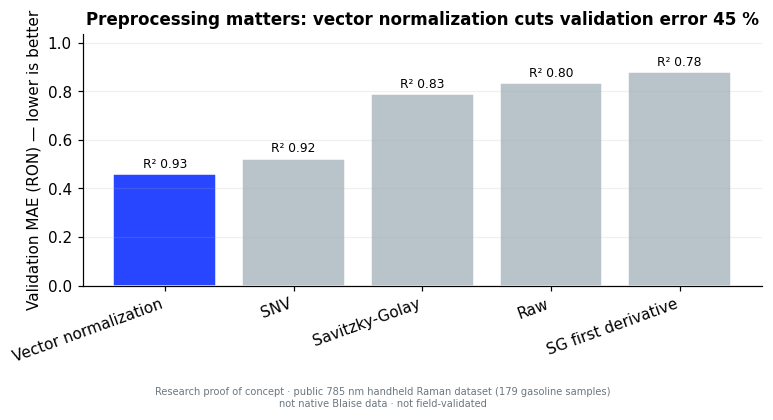

In [3]:
# ==================================================================
# step 3/10 · baselines + preprocessing comparison (validation only)
# ==================================================================
def pipe_pls():
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("m", PLSRegression(n_components=10))])
def pipe_svr_base():
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                     ("m", SVR(kernel="rbf", C=10, epsilon=0.05, gamma="scale"))])

pls = pipe_pls().fit(X_train, y_train);      m_pls = metrics(y_val, pls.predict(X_val))
svr0 = pipe_svr_base().fit(X_train, y_train); m_svr0 = metrics(y_val, svr0.predict(X_val))

t03 = pd.DataFrame([
    {"Model": "PLS (10 components), raw spectra", **{k: m_pls[k] for k in ["R2", "MAE", "RMSE", "Bias", "W02", "W07"]}},
    {"Model": "RBF-SVR, raw spectra",             **{k: m_svr0[k] for k in ["R2", "MAE", "RMSE", "Bias", "W02", "W07"]}}])
t03.columns = ["Model", "R²", "MAE (RON)", "RMSE (RON)", "Bias (RON)", "Within ±0.2 RON (%)", "Within ±0.7 RON (%)"]
save_table(t03, "t03_baseline_validation", "Table 3 — Baseline models on the validation set (36 samples)",
           note="Trained on the 107 training samples, evaluated on validation. Test set untouched.",
           use="Pitch field 5 (technical approach)", decimals={"Within ±0.2 RON (%)": 1, "Within ±0.7 RON (%)": 1})

def pp_raw(X):  return X.copy()
def pp_vec(X):  return vector_normalize(X)
def pp_snv(X):
    s = X.std(axis=1, keepdims=True); s[s == 0] = 1
    return (X - X.mean(axis=1, keepdims=True)) / s
def pp_sg(X):   return savgol_filter(X, window_length=21, polyorder=2, axis=1)
def pp_sg1(X):  return savgol_filter(X, window_length=21, polyorder=2, deriv=1, axis=1)
PREPROC = {"Raw": pp_raw, "Vector normalization": pp_vec, "SNV": pp_snv, "Savitzky-Golay": pp_sg, "SG first derivative": pp_sg1}

rows = []
for name, fn in PREPROC.items():
    mdl = Pipeline([("sc", StandardScaler()), ("m", SVR(kernel="rbf", C=10, epsilon=0.05, gamma="scale"))])
    mdl.fit(fn(X_train), y_train)
    rows.append({"Preprocessing": name, **metrics(y_val, mdl.predict(fn(X_val)))})
t04 = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
t04_disp = t04.rename(columns={"R2": "R²", "MAE": "MAE (RON)", "RMSE": "RMSE (RON)", "Bias": "Bias (RON)",
                               "W02": "Within ±0.2 RON (%)", "W07": "Within ±0.7 RON (%)"})
save_table(t04_disp, "t04_preprocessing_validation", "Table 4 — Preprocessing comparison (RBF-SVR, validation set)",
           note="Vector normalization gave the best validation performance and was selected. Test set untouched.",
           use="Pitch field 5 (why the pipeline looks the way it does)", decimals={"Within ±0.2 RON (%)": 1, "Within ±0.7 RON (%)": 1})

fig, ax = plt.subplots(figsize=(7.2, 3.8))
cols = [PALETTE["accent"] if n == "Vector normalization" else "#b9c3ca" for n in t04["Preprocessing"]]
bars = ax.bar(t04["Preprocessing"], t04["MAE"], color=cols, edgecolor="white")
for b, r2 in zip(bars, t04["R2"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.015, f"R² {r2:.2f}", ha="center", va="bottom", fontsize=8)
_raw_mae = float(t04.loc[t04["Preprocessing"] == "Raw", "MAE"].iloc[0]); _vec_mae = float(t04.loc[t04["Preprocessing"] == "Vector normalization", "MAE"].iloc[0])
PREPROC_GAIN = 100 * (1 - _vec_mae / _raw_mae)
ax.set(ylabel="Validation MAE (RON) — lower is better", title=f"Preprocessing matters: vector normalization cuts validation error {PREPROC_GAIN:.0f} %")
ax.set_ylim(0, t04["MAE"].max() * 1.18); plt.setp(ax.get_xticklabels(), rotation=20, ha="right"); ax.grid(axis="x", visible=False)
save_figure(fig, "fig03_preprocessing_comparison", "Preprocessing comparison",
            "Validation MAE (bars) and R² (labels) for five spectral preprocessing options with the same RBF-SVR. Selected option highlighted.",
            use="Pitch field 5 (technical approach)")

## 4 · SVR hyper-parameter search (140 configurations, validation set only)
Vector-normalized spectra, median imputation and scaling fitted on the training split only. The report's frozen configuration is checked against the grid winner. Outputs: **t05** (top 15; full grid saved as CSV), **fig04** (MAE heat-map).

Grid winner: C=10.0 epsilon=0.01 gamma=0.0003  | MAE=0.4128
✓ Grid winner equals the frozen configuration.


**Table 5 — Top 15 of 140 SVR configurations (validation set)**

,C,epsilon,gamma,R²,MAE (RON),RMSE (RON),Bias (RON),Within ±0.2 RON (%),Within ±0.7 RON (%)
0,10.0,0.01,0.0003,0.949830,0.412769,0.527073,-0.042820,33.333333,88.888889
1,10.0,0.03,0.0003,0.949152,0.415562,0.530622,-0.040789,27.777778,88.888889
2,10.0,0.05,0.0003,0.948352,0.418741,0.534782,-0.040621,30.555556,88.888889
3,30.0,0.10,0.0001,0.949523,0.421600,0.528684,-0.021194,25.000000,86.111111
4,10.0,0.10,0.0003,0.946011,0.426727,0.546767,-0.045346,36.111111,86.111111
5,30.0,0.05,0.0001,0.948824,0.427905,0.532332,-0.014066,22.222222,86.111111
6,30.0,0.03,0.0001,0.948685,0.429563,0.533055,-0.013505,22.222222,86.111111
7,30.0,0.01,0.0001,0.948506,0.430675,0.533984,-0.012436,19.444444,86.111111
8,10.0,0.20,0.0001,0.937042,0.431283,0.590437,0.015205,30.555556,86.111111
9,30.0,0.20,0.0001,0.945514,0.432357,0.549277,-0.051769,30.555556,83.333333


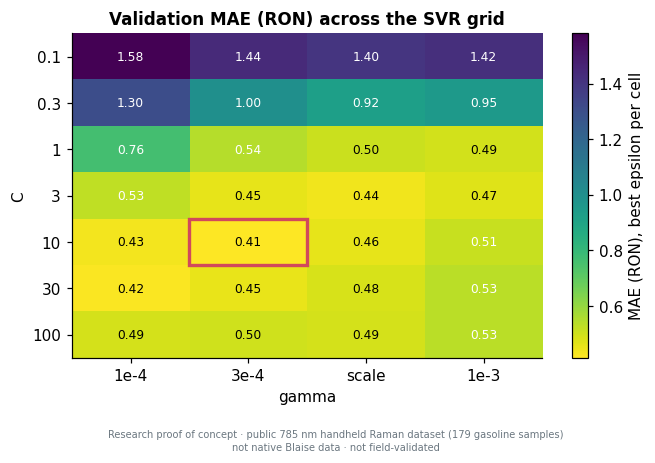

In [4]:
# ==================================================================
# step 4/10 · SVR grid search on validation (140 configurations)
# ==================================================================
Xtr_v, Xva_v = vector_normalize(X_train), vector_normalize(X_val)
imp_g = SimpleImputer(strategy="median").fit(Xtr_v)
sc_g = StandardScaler().fit(imp_g.transform(Xtr_v))
Xtr_g, Xva_g = sc_g.transform(imp_g.transform(Xtr_v)), sc_g.transform(imp_g.transform(Xva_v))

C_vals, EPS_vals, GAMMA_vals = [0.1, 0.3, 1, 3, 10, 30, 100], [0.01, 0.03, 0.05, 0.1, 0.2], ["scale", 0.0001, 0.0003, 0.001]
grid_rows = []
for C in C_vals:
    for eps in EPS_vals:
        for g in GAMMA_vals:
            p = SVR(kernel="rbf", C=C, epsilon=eps, gamma=g).fit(Xtr_g, y_train).predict(Xva_g)
            grid_rows.append({"C": float(C), "epsilon": eps, "gamma": str(g), **metrics(y_val, p)})
grid = pd.DataFrame(grid_rows).sort_values(["MAE", "RMSE"]).reset_index(drop=True)
assert len(grid) == 140
best = grid.iloc[0]
print(f"Grid winner: C={best.C} epsilon={best.epsilon} gamma={best.gamma}  | MAE={best.MAE:.4f}")
same = (best.C == FROZEN["C"] and best.epsilon == FROZEN["epsilon"] and float(best.gamma) == FROZEN["gamma"]) if best.gamma != "scale" else False
print("✓ Grid winner equals the frozen configuration." if same else
      "⚠ Grid winner differs from the frozen configuration — the FROZEN parameters from the master report are still used.")

ren = {"R2": "R²", "MAE": "MAE (RON)", "RMSE": "RMSE (RON)", "Bias": "Bias (RON)", "W02": "Within ±0.2 RON (%)", "W07": "Within ±0.7 RON (%)"}
save_table(grid.head(15).rename(columns=ren), "t05_svr_grid_top15", "Table 5 — Top 15 of 140 SVR configurations (validation set)",
           note="Ranked by validation MAE, then RMSE. The frozen configuration is C=10, epsilon=0.01, gamma=0.0003. Test set untouched.",
           use="Pitch field 5 (model selection discipline)", decimals={"Within ±0.2 RON (%)": 1, "Within ±0.7 RON (%)": 1})
save_table(grid.rename(columns=ren), "t05b_svr_grid_full", "Full SVR grid", md=False, show=False)

gam_order = ["0.0001", "0.0003", "scale", "0.001"]; gam_lab = ["1e-4", "3e-4", "scale", "1e-3"]
Z = np.array([[grid[(grid.C == float(c)) & (grid.gamma == g)]["MAE"].min() for g in gam_order] for c in C_vals])
fig, ax = plt.subplots(figsize=(6.2, 4.2))
im = ax.imshow(Z, cmap="viridis_r", aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels(gam_lab); ax.set_yticks(range(len(C_vals))); ax.set_yticklabels([f"{c:g}" for c in C_vals])
for i in range(Z.shape[0]):
    for j in range(Z.shape[1]):
        ax.text(j, i, f"{Z[i, j]:.2f}", ha="center", va="center", fontsize=8, color="black" if Z[i, j] < np.nanmedian(Z) else "white")
fi, fj = C_vals.index(10), gam_order.index("0.0003")
ax.add_patch(Rectangle((fj - .5, fi - .5), 1, 1, fill=False, ec=PALETTE["test"], lw=2.2))
ax.set(xlabel="gamma", ylabel="C", title="Validation MAE (RON) across the SVR grid"); ax.grid(False)
fig.colorbar(im, ax=ax, label="MAE (RON), best epsilon per cell")
save_figure(fig, "fig04_svr_grid_heatmap", "SVR grid heat-map",
            "Validation MAE for each C × gamma pair (best epsilon per cell). Red outline marks the frozen configuration.",
            use="Pitch field 5 (optional — shows the model was tuned without the test set)")

## 5 · Frozen model → official test set (evaluated once)
The model is refit on all 143 development samples with the frozen configuration and scored on the 36-sample held-out test set **exactly once**. Outputs: **t06** (frozen configuration), **t07** (test metrics), **t08** (per-sample predictions), **t09** (bootstrap 95 % CIs — *added analysis*), **fig05**, **fig06**.

TEST  R²=0.9655  MAE=0.3343  RMSE=0.4330  bias=-0.0814  ±0.2=33.3%  ±0.7=83.3%


**Table 6 — Frozen model configuration**

,Item,Setting
0,Preprocessing,Vector normalization → median imputation → sta...
1,Model,RBF support-vector regression (SVR)
2,C / epsilon / gamma,10 / 0.01 / 0.0003
3,Fitted on,143 development samples (training + validation)
4,Evaluated on,"36 held-out test samples, evaluated once"
5,Tuning on test set,None


**Table 7 — Final held-out test performance (36 samples)**

,Metric,Result
0,R²,0.965533
1,MAE (RON),0.334262
2,RMSE (RON),0.433016
3,Bias (RON),-0.081438
4,Within ±0.2 RON (%),33.333333
5,Within ±0.7 RON (%),83.333333
6,Test samples,36.000000


**Table 8 — Per-sample test predictions (sorted by absolute error)**

,Actual RON,Predicted RON,Error (RON),Absolute error (RON)
0,96.0,96.010249,0.010249,0.010249
1,96.4,96.389066,-0.010934,0.010934
2,96.1,96.120381,0.020381,0.020381
3,96.0,95.973459,-0.026541,0.026541
4,96.5,96.460812,-0.039188,0.039188
5,102.1,102.034361,-0.065639,0.065639
6,101.9,101.967946,0.067946,0.067946
7,96.4,96.471021,0.071021,0.071021
8,96.1,96.003038,-0.096962,0.096962
9,102.0,102.097387,0.097387,0.097387


**Table 9 — Test metrics with bootstrap 95% confidence intervals (added analysis)**

,Metric,Point estimate,95% CI low,95% CI high
0,R²,0.965533,0.931004,0.981672
1,MAE (RON),0.334262,0.248222,0.428758
2,RMSE (RON),0.433016,0.329345,0.528054
3,Within ±0.7 RON (%),83.333333,69.444444,94.444444


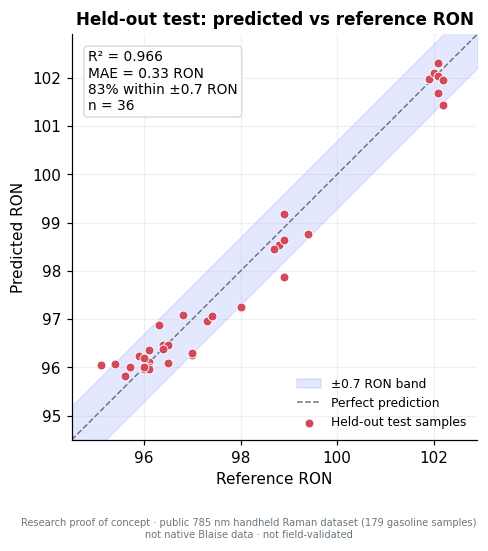

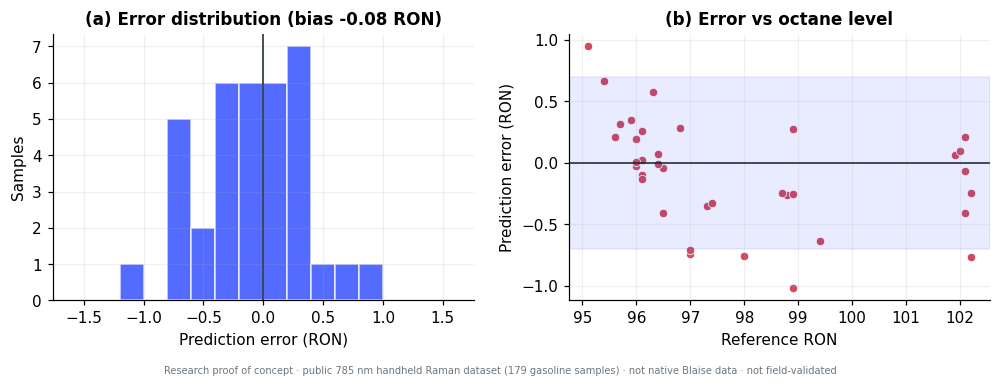

In [5]:
# ==================================================================
# step 5/10 · FROZEN MODEL — official test evaluation (once)
# ==================================================================
Xd, Xt = vector_normalize(X_dev), vector_normalize(X_test)
imp_f = SimpleImputer(strategy="median").fit(Xd); Xd = imp_f.transform(Xd); Xt = imp_f.transform(Xt)
sc_f = StandardScaler().fit(Xd);                  Xd = sc_f.transform(Xd);  Xt = sc_f.transform(Xt)
final_model = SVR(kernel="rbf", **FROZEN).fit(Xd, y_dev)
test_pred = final_model.predict(Xt)                      # ← the one and only test evaluation
mt = metrics(y_test, test_pred)
print(f"TEST  R²={mt['R2']:.4f}  MAE={mt['MAE']:.4f}  RMSE={mt['RMSE']:.4f}  bias={mt['Bias']:+.4f}  ±0.2={mt['W02']:.1f}%  ±0.7={mt['W07']:.1f}%")

t06 = pd.DataFrame([
    {"Item": "Preprocessing", "Setting": "Vector normalization → median imputation → standard scaling"},
    {"Item": "Model", "Setting": "RBF support-vector regression (SVR)"},
    {"Item": "C / epsilon / gamma", "Setting": f"{FROZEN['C']:g} / {FROZEN['epsilon']:g} / {FROZEN['gamma']:g}"},
    {"Item": "Fitted on", "Setting": f"{len(y_dev)} development samples (training + validation)"},
    {"Item": "Evaluated on", "Setting": f"{len(y_test)} held-out test samples, evaluated once"},
    {"Item": "Tuning on test set", "Setting": "None"}])
save_table(t06, "t06_frozen_model_config", "Table 6 — Frozen model configuration",
           note="Hyper-parameters were frozen on validation data before the official test set was evaluated.", use="Pitch field 5 (technical approach)")

t07 = pd.DataFrame([
    {"Metric": "R²", "Result": mt["R2"]}, {"Metric": "MAE (RON)", "Result": mt["MAE"]},
    {"Metric": "RMSE (RON)", "Result": mt["RMSE"]}, {"Metric": "Bias (RON)", "Result": mt["Bias"]},
    {"Metric": "Within ±0.2 RON (%)", "Result": mt["W02"]}, {"Metric": "Within ±0.7 RON (%)", "Result": mt["W07"]},
    {"Metric": "Test samples", "Result": len(y_test)}])
save_table(t07, "t07_final_test_metrics", "Table 7 — Final held-out test performance (36 samples)",
           note="Public dataset, different instrument and wavelength than Blaise. Research proof of concept; not field performance and not Blaise performance.",
           use="Pitch field 5 and field 7 (headline numbers)", decimals={"Result": 4})

t08 = pd.DataFrame({"Actual RON": y_test, "Predicted RON": test_pred, "Error (RON)": test_pred - y_test,
                    "Absolute error (RON)": np.abs(test_pred - y_test)}).sort_values("Absolute error (RON)").reset_index(drop=True)
save_table(t08, "t08_final_test_predictions", "Table 8 — Per-sample test predictions (sorted by absolute error)",
           note="Error = predicted − actual.", use="Supporting table / appendix", decimals=3)

def boot_ci(y, p, n=BOOT_N, seed=BOOT_SEED):
    rng = np.random.default_rng(seed); idx = rng.integers(0, len(y), size=(n, len(y)))
    acc = {k: [] for k in ["R2", "MAE", "RMSE", "W07"]}
    for ii in idx:
        if np.ptp(y[ii]) == 0: continue
        m = metrics(y[ii], p[ii])
        for k in acc: acc[k].append(m[k])
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in acc.items()}
ci = boot_ci(y_test, test_pred)
t09 = pd.DataFrame([
    {"Metric": "R²", "Point estimate": mt["R2"], "95% CI low": ci["R2"][0], "95% CI high": ci["R2"][1]},
    {"Metric": "MAE (RON)", "Point estimate": mt["MAE"], "95% CI low": ci["MAE"][0], "95% CI high": ci["MAE"][1]},
    {"Metric": "RMSE (RON)", "Point estimate": mt["RMSE"], "95% CI low": ci["RMSE"][0], "95% CI high": ci["RMSE"][1]},
    {"Metric": "Within ±0.7 RON (%)", "Point estimate": mt["W07"], "95% CI low": ci["W07"][0], "95% CI high": ci["W07"][1]}])
save_table(t09, "t09_test_metrics_bootstrap_ci", "Table 9 — Test metrics with bootstrap 95% confidence intervals (added analysis)",
           note=f"{BOOT_N} bootstrap resamples of the 36 test samples. Captures sampling uncertainty only — not instrument, operator, batch or field variability. Not in the master report.",
           use="Pitch field 5 / 7 — shows honest uncertainty", decimals={"Point estimate": 4, "95% CI low": 4, "95% CI high": 4})

# ---- fig05 predicted vs actual ----
lo, hi = min(y_test.min(), test_pred.min()) - .6, max(y_test.max(), test_pred.max()) + .6
fig, ax = plt.subplots(figsize=(5.2, 5.0))
ax.fill_between([lo, hi], [lo - .7, hi - .7], [lo + .7, hi + .7], color=PALETTE["accent"], alpha=.12, label="±0.7 RON band")
ax.plot([lo, hi], [lo, hi], "--", color=PALETTE["grey"], lw=1, label="Perfect prediction")
ax.scatter(y_test, test_pred, s=34, color=PALETTE["test"], edgecolor="white", lw=.6, zorder=3, label="Held-out test samples")
ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="Reference RON", ylabel="Predicted RON", title="Held-out test: predicted vs reference RON"); ax.set_aspect("equal")
ax.text(.04, .96, f"R² = {mt['R2']:.3f}\nMAE = {mt['MAE']:.2f} RON\n{mt['W07']:.0f}% within ±0.7 RON\nn = {len(y_test)}", transform=ax.transAxes, va="top", fontsize=9,
        bbox=dict(boxstyle="round", fc="white", ec="#d5dee3"))
ax.legend(loc="lower right", frameon=False, fontsize=8)
save_figure(fig, "fig05_test_predicted_vs_actual", "Held-out test: predicted vs reference RON",
            "Frozen RBF-SVR on the 36 held-out test samples; shaded band is ±0.7 RON.", use="Pitch field 5 (feasibility evidence) — main results figure")

# ---- fig06 residual diagnostics ----
err = test_pred - y_test
fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.5))
ax[0].hist(err, bins=np.arange(-1.6, 1.61, 0.2), color=PALETTE["accent"], alpha=.8, edgecolor="white"); ax[0].axvline(0, color=PALETTE["ink"], lw=1)
ax[0].set(xlabel="Prediction error (RON)", ylabel="Samples", title=f"(a) Error distribution (bias {mt['Bias']:+.2f} RON)")
ax[1].scatter(y_test, err, s=30, color=PALETTE["test"], edgecolor="white", lw=.5); ax[1].axhline(0, color=PALETTE["ink"], lw=1)
ax[1].axhspan(-.7, .7, color=PALETTE["accent"], alpha=.1)
ax[1].set(xlabel="Reference RON", ylabel="Prediction error (RON)", title="(b) Error vs octane level")
save_figure(fig, "fig06_test_residuals", "Test residual diagnostics",
            "Distribution of test prediction errors (a) and error against reference RON (b); band is ±0.7 RON.", use="Appendix / honesty figure")

## 6 · Applicability domain — leakage-free 5-fold cross-validation (development set only)
Normalization is row-wise; imputer, scaler, SVR and the 5-nearest-neighbour index are all fitted on each fold's training portion only. **The official test set is not used here**, so the exploratory thresholds come from development data alone. Outputs: **t10**, **t11**, **t12**, **fig07**, **fig08**.

CV: n=143  MAE=0.5902  RMSE=1.0147  bias=+0.0485  corr(dist, |err|)=0.4766
Exploratory thresholds: review > 33.3542 | lab > 39.9816


**Table 10 — Prediction error by spectral-distance group (5-fold CV, 143 development samples)**

,Spectral-distance group,Samples,MAE (RON),Median abs. error (RON),Max abs. error (RON),Mean 5-NN distance
0,Lowest 50%,72,0.393659,0.261501,3.432745,15.944669
1,50–75%,35,0.595957,0.492279,2.177461,30.029450
2,75–90%,21,0.592669,0.586394,1.514472,35.782371
3,Highest 10%,15,1.516778,0.611200,6.155160,52.704286


**Table 11 — Distance quantiles and exploratory decision thresholds**

,Item,Value,Status
0,50th percentile of mean 5-NN distance,23.552684,descriptive
1,75th percentile,33.354215,descriptive
2,80th percentile,34.861290,descriptive
3,90th percentile,39.981556,descriptive
4,95th percentile,48.252804,descriptive
5,Review candidate: distance >,33.354215,EXPLORATORY — not a validated operating limit
6,Laboratory-confirmation candidate: distance >,39.981556,EXPLORATORY — not a validated operating limit


**Table 12 — Three-tier decision concept on cross-validated development data (added summary)**

,Tier,Rule (mean 5-NN distance),Samples,Share (%),MAE (RON),Within ±0.7 RON (%),Max abs. error (RON)
0,Routine screening,distance ≤ 33.35,107,74.825175,0.459831,78.504673,3.432745
1,Review required,33.35 < distance ≤ 39.98,21,14.685315,0.592669,71.428571,1.514472
2,Laboratory confirmation,distance > 39.98,15,10.489510,1.516778,60.000000,6.155160


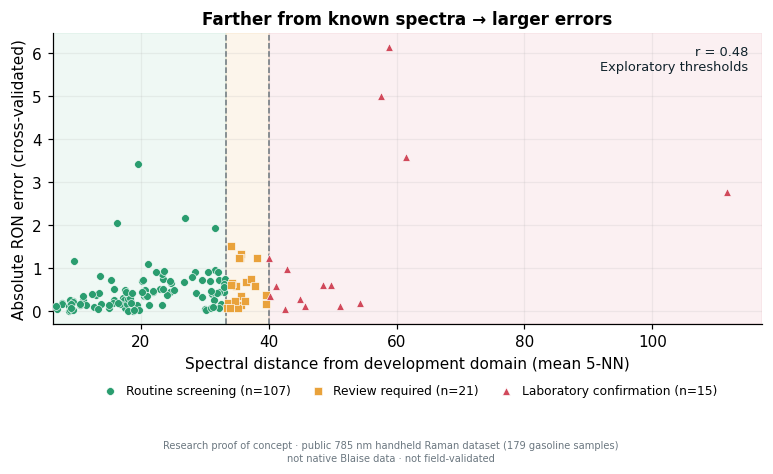

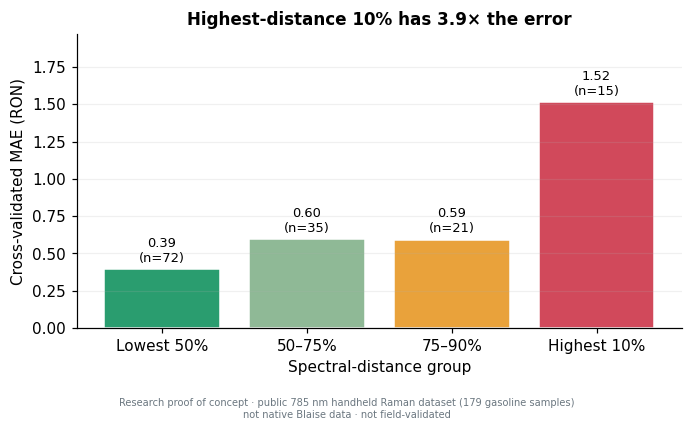

In [6]:
# ==================================================================
# step 6/10 · applicability domain (leakage-free CV, dev set only)
# ==================================================================
kf = KFold(n_splits=CV_SPLITS, shuffle=True, random_state=CV_SEED)
recs = []
for fold, (fit_idx, hold_idx) in enumerate(kf.split(X_dev), start=1):
    Xf, Xh = vector_normalize(X_dev[fit_idx]), vector_normalize(X_dev[hold_idx])
    im = SimpleImputer(strategy="median").fit(Xf); Xf, Xh = im.transform(Xf), im.transform(Xh)
    sc = StandardScaler().fit(Xf);                 Xf, Xh = sc.transform(Xf), sc.transform(Xh)
    pred = SVR(kernel="rbf", **FROZEN).fit(Xf, y_dev[fit_idx]).predict(Xh)
    dist, _ = NearestNeighbors(n_neighbors=5).fit(Xf).kneighbors(Xh)
    for i, s in enumerate(hold_idx):
        recs.append({"fold": fold, "sample_index": int(s), "actual_RON": float(y_dev[s]), "predicted_RON": float(pred[i]),
                     "absolute_error_RON": float(abs(y_dev[s] - pred[i])), "nearest_distance": float(dist[i, 0]),
                     "mean_5NN_distance": float(dist[i].mean())})
cv_df = pd.DataFrame(recs)
cv_corr = float(cv_df[["mean_5NN_distance", "absolute_error_RON"]].corr().iloc[0, 1])
cv_mae = float(cv_df["absolute_error_RON"].mean())
cv_rmse = float(np.sqrt(np.mean((cv_df["actual_RON"] - cv_df["predicted_RON"]) ** 2)))
cv_bias = float((cv_df["predicted_RON"] - cv_df["actual_RON"]).mean())
qs = cv_df["mean_5NN_distance"].quantile([0.50, 0.75, 0.80, 0.90, 0.95])
q50, q75, q90 = float(qs.loc[0.50]), float(qs.loc[0.75]), float(qs.loc[0.90])
print(f"CV: n={len(cv_df)}  MAE={cv_mae:.4f}  RMSE={cv_rmse:.4f}  bias={cv_bias:+.4f}  corr(dist, |err|)={cv_corr:.4f}")
print(f"Exploratory thresholds: review > {q75:.4f} | lab > {q90:.4f}")

GROUPS = ["Lowest 50%", "50–75%", "75–90%", "Highest 10%"]
cv_df["distance_group"] = pd.Categorical(cv_df["mean_5NN_distance"].apply(
    lambda d: GROUPS[0] if d <= q50 else GROUPS[1] if d <= q75 else GROUPS[2] if d <= q90 else GROUPS[3]), categories=GROUPS, ordered=True)
grp = (cv_df.groupby("distance_group", observed=True)
       .agg(samples=("absolute_error_RON", "size"), MAE=("absolute_error_RON", "mean"), median_error=("absolute_error_RON", "median"),
            max_error=("absolute_error_RON", "max"), mean_distance=("mean_5NN_distance", "mean")).reset_index())
mae_low, mae_high = float(grp.loc[0, "MAE"]), float(grp.loc[len(grp) - 1, "MAE"]); ad_ratio = mae_high / mae_low
t10 = grp.rename(columns={"distance_group": "Spectral-distance group", "samples": "Samples", "MAE": "MAE (RON)",
                          "median_error": "Median abs. error (RON)", "max_error": "Max abs. error (RON)", "mean_distance": "Mean 5-NN distance"})
save_table(t10, "t10_ad_error_by_distance_group", "Table 10 — Prediction error by spectral-distance group (5-fold CV, 143 development samples)",
           note=f"Highest-distance 10% has {ad_ratio:.1f}× the MAE of the lowest-distance 50%. Correlation between distance and absolute error r = {cv_corr:.3f}: a meaningful but imperfect signal.",
           use="Pitch field 3 (uniqueness) — the applicability-domain evidence", decimals={"Mean 5-NN distance": 2})
save_table(cv_df, "t10b_cv_per_sample", "Per-sample CV results", md=False, show=False)

t11 = pd.DataFrame([
    {"Item": "50th percentile of mean 5-NN distance", "Value": q50, "Status": "descriptive"},
    {"Item": "75th percentile", "Value": q75, "Status": "descriptive"},
    {"Item": "80th percentile", "Value": float(qs.loc[0.80]), "Status": "descriptive"},
    {"Item": "90th percentile", "Value": q90, "Status": "descriptive"},
    {"Item": "95th percentile", "Value": float(qs.loc[0.95]), "Status": "descriptive"},
    {"Item": "Review candidate: distance >", "Value": q75, "Status": "EXPLORATORY — not a validated operating limit"},
    {"Item": "Laboratory-confirmation candidate: distance >", "Value": q90, "Status": "EXPLORATORY — not a validated operating limit"}])
save_table(t11, "t11_ad_distance_thresholds", "Table 11 — Distance quantiles and exploratory decision thresholds",
           note="Derived from development-set cross-validation only. Must not be used for regulatory, safety, custody-transfer or certification decisions without independent validation.",
           use="Pitch field 5 — state clearly that thresholds are exploratory", decimals={"Value": 4})

def tier_of(d): return "Routine screening" if d <= q75 else "Review required" if d <= q90 else "Laboratory confirmation"
TIERS = ["Routine screening", "Review required", "Laboratory confirmation"]
cv_df["tier"] = pd.Categorical(cv_df["mean_5NN_distance"].apply(tier_of), categories=TIERS, ordered=True)
rows = []
for t, rule in zip(TIERS, [f"distance ≤ {q75:.2f}", f"{q75:.2f} < distance ≤ {q90:.2f}", f"distance > {q90:.2f}"]):
    sub = cv_df[cv_df["tier"] == t]
    rows.append({"Tier": t, "Rule (mean 5-NN distance)": rule, "Samples": len(sub), "Share (%)": 100 * len(sub) / len(cv_df),
                 "MAE (RON)": sub["absolute_error_RON"].mean(), "Within ±0.7 RON (%)": 100 * (sub["absolute_error_RON"] <= 0.7).mean(),
                 "Max abs. error (RON)": sub["absolute_error_RON"].max()})
t12 = pd.DataFrame(rows)
save_table(t12, "t12_ad_decision_tiers", "Table 12 — Three-tier decision concept on cross-validated development data (added summary)",
           note="Thresholds were derived from this same cross-validation distribution, so tier shares are ~75/15/10% by construction and error figures are optimistic. Concept illustration only.",
           use="Pitch field 2 / 3 — supports the Routine / Review / Lab concept", decimals={"Share (%)": 1, "MAE (RON)": 3, "Within ±0.7 RON (%)": 1, "Max abs. error (RON)": 2})

# ---- fig07 distance vs error ----
fig, ax = plt.subplots(figsize=(7.2, 4.3))
ax.axvspan(0, q75, color=PALETTE["routine"], alpha=.07); ax.axvspan(q75, q90, color=PALETTE["review"], alpha=.10)
ax.axvspan(q90, cv_df["mean_5NN_distance"].max() * 1.05, color=PALETTE["lab"], alpha=.08)
for t, c, mk in zip(TIERS, [PALETTE["routine"], PALETTE["review"], PALETTE["lab"]], ["o", "s", "^"]):
    s = cv_df[cv_df["tier"] == t]
    ax.scatter(s["mean_5NN_distance"], s["absolute_error_RON"], s=26, color=c, marker=mk, edgecolor="white", lw=.4, label=f"{t} (n={len(s)})", zorder=3)
ax.axvline(q75, color=PALETTE["grey"], ls="--", lw=1); ax.axvline(q90, color=PALETTE["grey"], ls="--", lw=1)
ax.set(xlabel="Spectral distance from development domain (mean 5-NN)", ylabel="Absolute RON error (cross-validated)",
       title="Farther from known spectra → larger errors", xlim=(cv_df["mean_5NN_distance"].min() * 0.92, cv_df["mean_5NN_distance"].max() * 1.05))
ax.text(.98, .96, f"r = {cv_corr:.2f}\nExploratory thresholds", transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=PALETTE["ink"])
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, columnspacing=1.2, handletextpad=0.3)
save_figure(fig, "fig07_ad_distance_vs_error", "Applicability domain: distance vs error",
            "Leakage-free 5-fold CV on 143 development samples. Each point is a held-out sample; dashed lines are exploratory review / lab-confirmation candidates.",
            use="Pitch field 3 (uniqueness) — the key differentiator figure")

# ---- fig08 MAE by group ----
fig, ax = plt.subplots(figsize=(6.4, 3.9))
bars = ax.bar(grp["distance_group"].astype(str), grp["MAE"], color=[PALETTE["routine"], "#8fb996", PALETTE["review"], PALETTE["lab"]], edgecolor="white")
for b, n, m in zip(bars, grp["samples"], grp["MAE"]):
    ax.text(b.get_x() + b.get_width() / 2, m + .03, f"{m:.2f}\n(n={n})", ha="center", va="bottom", fontsize=8.5)
ax.set(ylabel="Cross-validated MAE (RON)", xlabel="Spectral-distance group", title=f"Highest-distance 10% has {ad_ratio:.1f}× the error", ylim=(0, grp["MAE"].max() * 1.3)); ax.grid(axis="x", visible=False)
save_figure(fig, "fig08_ad_error_by_group", "Error by spectral-distance group",
            "Cross-validated MAE by spectral-distance group on the 143 development samples.", use="Pitch field 3 / field 7")

## 7 · Decision-architecture diagram and pitch hero panels
**fig09** is the Raman → prediction + domain-distance → Routine / Review / Lab diagram for the template's "include a graphic or diagram" prompt. **fig10** is a compact two-panel hero sized for the one-page PDF; **fig11** is the same content in 16:9 for the 3-minute video.

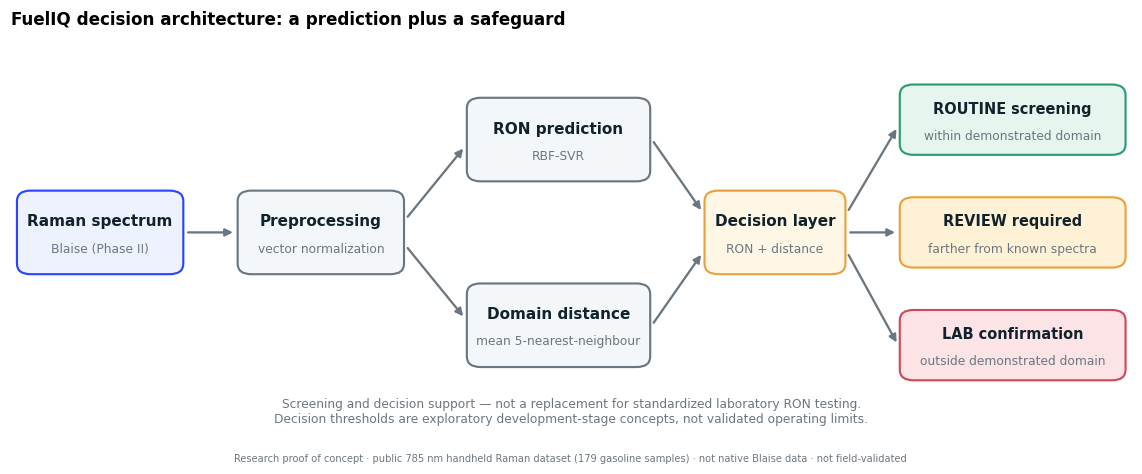

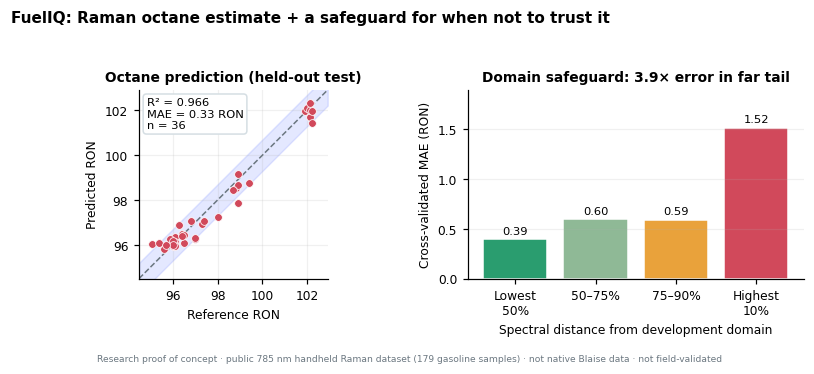

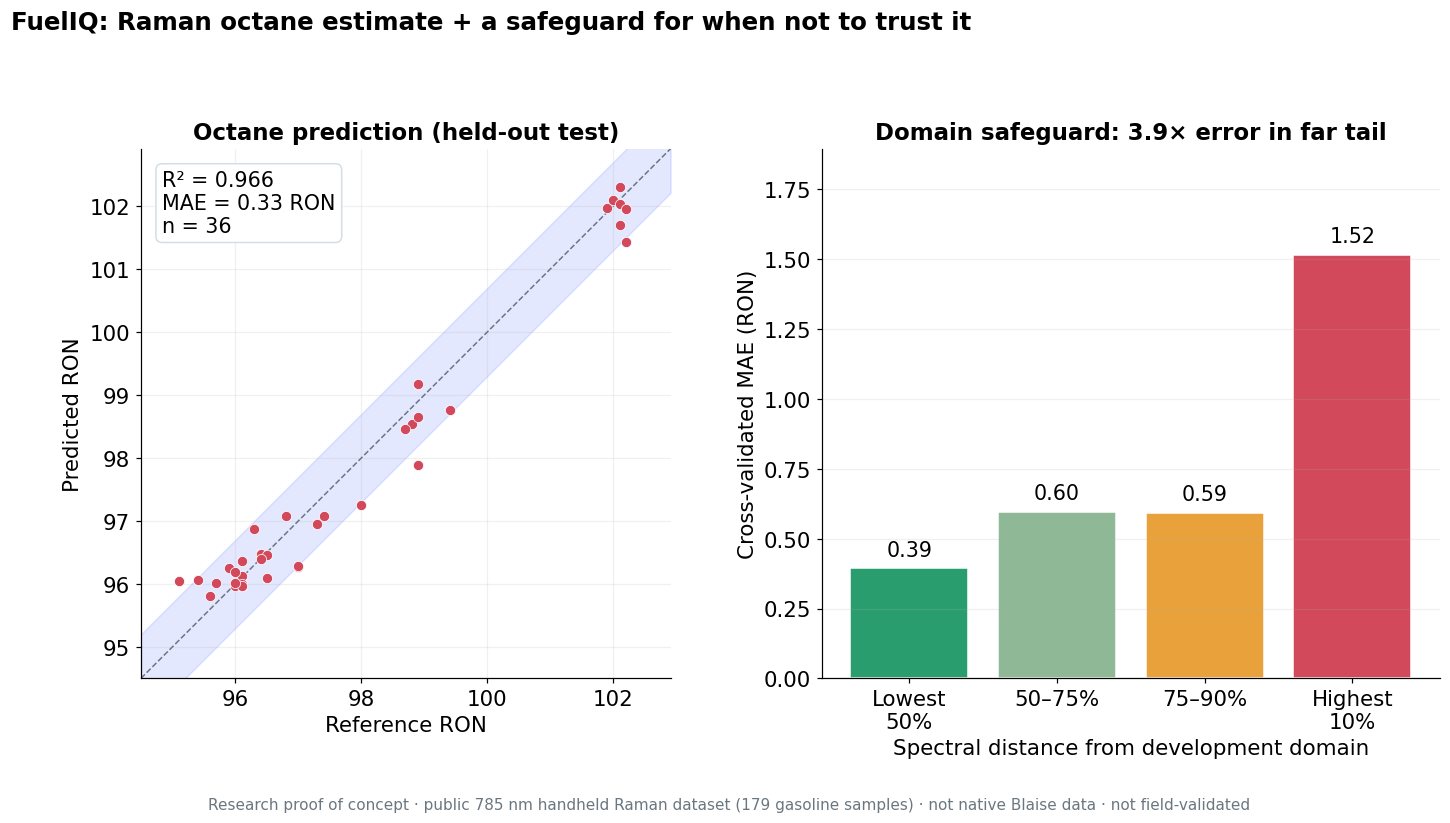

In [7]:
# ==================================================================
# step 7/10 · architecture diagram + hero panels
# ==================================================================
def _box(ax, x, y, w, h, fc, ec, title, sub=None, tfs=10, sfs=8, tc=None):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3,rounding_size=1.6", fc=fc, ec=ec, lw=1.4))
    ax.text(x + w / 2, y + h / 2 + (1.7 if sub else 0), title, ha="center", va="center", fontsize=tfs, fontweight="bold", color=tc or PALETTE["ink"])
    if sub: ax.text(x + w / 2, y + h / 2 - 2.4, sub, ha="center", va="center", fontsize=sfs, color=PALETTE["grey"] if tc is None else tc)
def _arrow(ax, x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=PALETTE["grey"], lw=1.5, shrinkA=2, shrinkB=2))

fig, ax = plt.subplots(figsize=(10.5, 4.3)); ax.set_xlim(0, 132); ax.set_ylim(0, 60); ax.axis("off"); ax.grid(False)
_box(ax, 1, 24, 19, 12, "#eef2ff", PALETTE["accent"], "Raman spectrum", "Blaise (Phase II)")
_box(ax, 27, 24, 19, 12, "#f4f7f9", PALETTE["grey"], "Preprocessing", "vector normalization")
_box(ax, 54, 38, 21, 12, "#f4f7f9", PALETTE["grey"], "RON prediction", "RBF-SVR")
_box(ax, 54, 10, 21, 12, "#f4f7f9", PALETTE["grey"], "Domain distance", "mean 5-nearest-neighbour")
_box(ax, 82, 24, 16, 12, "#fff7e6", PALETTE["review"], "Decision layer", "RON + distance")
_box(ax, 105, 42, 26, 10, "#e6f5ee", PALETTE["routine"], "ROUTINE screening", "within demonstrated domain", tfs=9.5, sfs=8)
_box(ax, 105, 25, 26, 10, "#fff1d6", PALETTE["review"], "REVIEW required", "farther from known spectra", tfs=9.5, sfs=8)
_box(ax, 105, 8, 26, 10, "#fbe3e6", PALETTE["lab"], "LAB confirmation", "outside demonstrated domain", tfs=9.5, sfs=8)
_arrow(ax, 20.5, 30, 26.5, 30); _arrow(ax, 46.5, 32, 53.5, 43); _arrow(ax, 46.5, 28, 53.5, 17)
_arrow(ax, 75.5, 44, 81.5, 33); _arrow(ax, 75.5, 16, 81.5, 27)
_arrow(ax, 98.5, 33, 104.5, 46); _arrow(ax, 98.5, 30, 104.5, 30); _arrow(ax, 98.5, 27, 104.5, 13)
ax.text(66, 3, "Screening and decision support — not a replacement for standardized laboratory RON testing.\nDecision thresholds are exploratory development-stage concepts, not validated operating limits.",
        ha="center", va="center", fontsize=8, color=PALETTE["grey"])
ax.set_title("FuelIQ decision architecture: a prediction plus a safeguard", loc="left")
save_figure(fig, "fig09_decision_architecture", "FuelIQ decision architecture",
            "Raman spectrum → preprocessing → RON prediction and domain-distance analysis → Routine / Review / Laboratory-confirmation status.",
            use="Pitch field 2 (Proposed Solution) — the template's graphic/diagram slot; also video opening")

def make_hero(stem, figsize, fs, title, caption, use, footer_size):
    with plt.rc_context({"font.size": fs, "axes.titlesize": fs + 1}):
        fig, ax = plt.subplots(1, 2, figsize=figsize, gridspec_kw={"width_ratios": [1, 1]})
        a = ax[0]; lo_, hi_ = min(y_test.min(), test_pred.min()) - .6, max(y_test.max(), test_pred.max()) + .6
        a.fill_between([lo_, hi_], [lo_ - .7, hi_ - .7], [lo_ + .7, hi_ + .7], color=PALETTE["accent"], alpha=.12)
        a.plot([lo_, hi_], [lo_, hi_], "--", color=PALETTE["grey"], lw=1)
        a.scatter(y_test, test_pred, s=fs * 3.2, color=PALETTE["test"], edgecolor="white", lw=.5, zorder=3)
        a.set(xlim=(lo_, hi_), ylim=(lo_, hi_), xlabel="Reference RON", ylabel="Predicted RON", title="Octane prediction (held-out test)"); a.set_aspect("equal")
        a.text(.04, .96, f"R² = {mt['R2']:.3f}\nMAE = {mt['MAE']:.2f} RON\nn = {len(y_test)}", transform=a.transAxes, va="top", fontsize=fs - 0.5,
               bbox=dict(boxstyle="round", fc="white", ec="#d5dee3"))
        b = ax[1]
        bars = b.bar(["Lowest\n50%", "50–75%", "75–90%", "Highest\n10%"], grp["MAE"], color=[PALETTE["routine"], "#8fb996", PALETTE["review"], PALETTE["lab"]], edgecolor="white")
        for bb, m in zip(bars, grp["MAE"]): b.text(bb.get_x() + bb.get_width() / 2, m + .03, f"{m:.2f}", ha="center", va="bottom", fontsize=fs - 0.5)
        b.set(ylabel="Cross-validated MAE (RON)", xlabel="Spectral distance from development domain", title=f"Domain safeguard: {ad_ratio:.1f}× error in far tail", ylim=(0, grp["MAE"].max() * 1.25)); b.grid(axis="x", visible=False)
        fig.suptitle(title, fontsize=fs + 2, fontweight="bold", x=0.01, ha="left")
        fig.tight_layout(rect=(0, 0.045, 1, 0.93))
        fig.text(0.5, 0.008, CAVEAT_FOOTER, ha="center", va="bottom", fontsize=footer_size, color=PALETTE["grey"])
        fig.savefig(os.path.join(FIG_DIR, f"{stem}.png"), dpi=300, facecolor="white"); plt.show(); plt.close(fig)
    FIGS.append(dict(stem=stem, title="Pitch hero panel" + (" (16:9)" if figsize[0] > 10 else ""), caption=caption, use=use))

make_hero("fig10_pitch_hero_onepage", (7.4, 3.3), 8, "FuelIQ: Raman octane estimate + a safeguard for when not to trust it",
          "Two-panel summary for the one-page pitch: held-out test accuracy (left) and error growth with spectral distance (right).",
          "Pitch field 5 / header graphic for the one-page PDF — best single figure to include", 6)
make_hero("fig11_pitch_hero_16x9_video", (13.33, 7.5), 14, "FuelIQ: Raman octane estimate + a safeguard for when not to trust it",
          "Same content as fig10 in 16:9 for the 3-minute video.", "Video — results scene (keep the caveat footer visible)", 10)

## 8 · Headline numbers, report cross-check, limitations table
**t13** collects the pitch-ready numbers with the wording guard each one needs. **t14** recomputes every number quoted in the master report and compares it with this run. **t15** restates the report's limitations with the Phase II action for each.

In [8]:
# ==================================================================
# step 8/10 · headline numbers, report cross-check, limitations
# ==================================================================
fx = lambda v, d=3: f"{v:.{d}f}"
t13 = pd.DataFrame([
    {"Quantity": "Dataset", "Value": f"{len(y_all)} gasoline samples · {len(raman_cols):,} Raman variables · {WN_MIN:.0f}–{WN_MAX:.0f} cm⁻¹ · RON {y_all.min():.1f}–{y_all.max():.1f}",
     "Evidence level": "Public research dataset (785 nm handheld)", "Wording guard": "Say 'public handheld Raman dataset', never 'Blaise data'."},
    {"Quantity": "Held-out test R²", "Value": f"{fx(mt['R2'], 4)} (95% CI {fx(ci['R2'][0])}–{fx(ci['R2'][1])})", "Evidence level": "36-sample held-out test, same dataset", "Wording guard": "Research proof of concept; not field performance."},
    {"Quantity": "Held-out test MAE", "Value": f"{fx(mt['MAE'])} RON (95% CI {fx(ci['MAE'][0])}–{fx(ci['MAE'][1])})", "Evidence level": "36-sample held-out test", "Wording guard": "Screening estimate, not a lab-certified RON."},
    {"Quantity": "Held-out test RMSE", "Value": f"{fx(mt['RMSE'])} RON", "Evidence level": "36-sample held-out test", "Wording guard": "As above."},
    {"Quantity": "Within ±0.7 RON", "Value": f"{mt['W07']:.1f}% (95% CI {ci['W07'][0]:.1f}–{ci['W07'][1]:.1f}%)", "Evidence level": "36-sample held-out test", "Wording guard": "Small sample (n=36)."},
    {"Quantity": "Within ±0.2 RON", "Value": f"{mt['W02']:.1f}%", "Evidence level": "36-sample held-out test", "Wording guard": "Only about a third of predictions are this tight — do not oversell precision."},
    {"Quantity": "5-fold CV MAE (development)", "Value": f"{fx(cv_mae)} RON", "Evidence level": "Cross-validation, 143 samples", "Wording guard": "More conservative than the test figure; quote both if quoting either."},
    {"Quantity": "Distance ↔ error correlation", "Value": f"r = {fx(cv_corr)}", "Evidence level": "Cross-validation, development only", "Wording guard": "Meaningful but imperfect — 'a useful warning signal', not 'detects errors'."},
    {"Quantity": "Error in far tail vs core", "Value": f"{fx(mae_high)} vs {fx(mae_low)} RON ({ad_ratio:.1f}×)", "Evidence level": "Cross-validation, highest 10% vs lowest 50%", "Wording guard": "Same caveat as above."},
    {"Quantity": "Exploratory thresholds", "Value": f"review > {fx(q75, 2)} · lab > {fx(q90, 2)} (mean 5-NN distance)", "Evidence level": "Exploratory, development-set derived", "Wording guard": "NOT validated operating limits; never for regulatory, safety or custody-transfer decisions."}])
save_table(t13, "t13_headline_numbers", "Table 13 — Pitch-ready headline numbers and wording guards",
           note="Quote a number only together with its evidence level. All results are from a public dataset acquired on a different handheld Raman instrument.",
           use="Pitch field 7 (success metrics) and field 5; video narration")

# ---- t14 cross-check against master report ----
def pp(name, col): return float(t04.loc[t04["Preprocessing"] == name, col].iloc[0])
chk = [("PLS validation R²", 0.7066, m_pls["R2"], 6e-4), ("PLS validation MAE", 1.0039, m_pls["MAE"], 6e-4), ("PLS validation RMSE", 1.2747, m_pls["RMSE"], 6e-4),
       ("SVR (raw) validation R²", 0.7998, m_svr0["R2"], 6e-4), ("SVR (raw) validation MAE", 0.8337, m_svr0["MAE"], 6e-4), ("SVR (raw) validation RMSE", 1.0530, m_svr0["RMSE"], 6e-4)]
for nm, r2_, mae_, rm_ in [("Vector normalization", .9288, .4579, .6281), ("SNV", .9233, .5223, .6517), ("Savitzky-Golay", .8260, .7886, .9817), ("SG first derivative", .7800, .8786, 1.1037)]:
    chk += [(f"{nm} validation R²", r2_, pp(nm, "R2"), 6e-4), (f"{nm} validation MAE", mae_, pp(nm, "MAE"), 6e-4), (f"{nm} validation RMSE", rm_, pp(nm, "RMSE"), 6e-4)]
chk += [("Grid best validation R²", .9498, float(best.R2), 6e-4), ("Grid best validation MAE", .4128, float(best.MAE), 6e-4), ("Grid best validation RMSE", .5271, float(best.RMSE), 6e-4),
        ("Grid best validation bias", -.0428, float(best.Bias), 6e-4), ("Grid best within ±0.7 RON (%)", 88.9, float(best.W07), .06),
        ("Test R²", .9655, mt["R2"], 6e-4), ("Test MAE", .3343, mt["MAE"], 6e-4), ("Test RMSE", .4330, mt["RMSE"], 6e-4), ("Test bias", -.0814, mt["Bias"], 6e-4),
        ("Test within ±0.2 RON (%)", 33.3, mt["W02"], .06), ("Test within ±0.7 RON (%)", 83.3, mt["W07"], .06),
        ("CV MAE", .5902, cv_mae, 6e-4), ("CV RMSE", 1.0147, cv_rmse, 6e-4), ("CV bias", .0485, cv_bias, 6e-4), ("CV distance/error correlation", .4766, cv_corr, 6e-4),
        ("Distance quantile 50%", 23.55, q50, .006), ("Distance quantile 75%", 33.35, q75, .006), ("Distance quantile 80%", 34.86, float(qs.loc[.80]), .006),
        ("Distance quantile 90%", 39.98, q90, .006), ("Distance quantile 95%", 48.25, float(qs.loc[.95]), .006),
        ("Review threshold", 33.3542, q75, 6e-4), ("Lab threshold", 39.9816, q90, 6e-4), ("MAE ratio highest-10% / lowest-50%", 3.9, ad_ratio, .06)]
for g_, (n_, m_, md_, mx_) in zip(GROUPS, [(72, .3937, .2615, 3.4327), (35, .5960, .4923, 2.1775), (21, .5927, .5864, 1.5145), (15, 1.5168, .6112, 6.1552)]):
    r_ = grp[grp["distance_group"].astype(str) == g_].iloc[0]
    chk += [(f"CV group '{g_}' samples", n_, int(r_["samples"]), 0), (f"CV group '{g_}' MAE", m_, float(r_["MAE"]), 6e-4),
            (f"CV group '{g_}' median error", md_, float(r_["median_error"]), 6e-4), (f"CV group '{g_}' max error", mx_, float(r_["max_error"]), 6e-4)]
t14 = pd.DataFrame([{"Quantity": q, "Master report": rv, "This run": tv, "Difference": tv - rv, "Status": "MATCH" if abs(tv - rv) <= tol else "DIFFERS"} for q, rv, tv, tol in chk])
n_diff = int((t14["Status"] == "DIFFERS").sum()); REPRO_OK = n_diff == 0
save_table(t14, "t14_report_reproducibility_check", "Table 14 — Cross-check: master report vs this run",
           note=("All report numbers reproduced." if REPRO_OK else f"{n_diff} value(s) DIFFER — review before quoting; library versions or dataset revisions can shift results slightly."),
           use="Internal QA — do not paste into the pitch", decimals={"Master report": 4, "This run": 4, "Difference": 5})
print("\n" + "=" * 70)
print(f"✓ REPORT CROSS-CHECK: all {len(t14)} numbers reproduced." if REPRO_OK else f"⚠ REPORT CROSS-CHECK: {n_diff} of {len(t14)} numbers DIFFER — open t14 before quoting results.")
print("=" * 70)

t15 = pd.DataFrame([
    {"Limitation": "Dataset size (179 samples)", "What it means": "Proof of concept only; not enough to establish broad field generalization.", "Phase II action": "Multi-supplier, multi-grade, multi-batch campaign on native Blaise."},
    {"Limitation": "Different instrument and wavelength (785 nm research handheld)", "What it means": "Results cannot be presented as Blaise performance.", "Phase II action": "Acquire native Blaise spectra; re-fit and re-validate end to end."},
    {"Limitation": "Test set is a subset of the same dataset", "What it means": "Not an independent field campaign.", "Phase II action": "Split by physical sample/batch; independent lab RON for every sample."},
    {"Limitation": "No environmental robustness evidence", "What it means": "Temperature, containers, operators, instruments, suppliers, geometry and contamination not tested.", "Phase II action": "Vary each factor deliberately across acquisition sessions."},
    {"Limitation": "Not an ASTM-compliant RON method", "What it means": "Position as screening and decision support, never as lab certification.", "Phase II action": "Keep lab confirmation in the workflow; engage standards experts."},
    {"Limitation": "Applicability-domain thresholds are exploratory", "What it means": "Derived from development-set CV; correlation r is moderate.", "Phase II action": "Validate and recalibrate thresholds on independent native-Blaise samples."}])
save_table(t15, "t15_limitations_and_phase2", "Table 15 — Limitations and the Phase II validation plan",
           note="From the master technical report, sections 15–16.", use="Pitch field 5 (feasibility honesty) — shows the validation path is planned")

**Table 13 — Pitch-ready headline numbers and wording guards**

,Quantity,Value,Evidence level,Wording guard
0,Dataset,"179 gasoline samples · 1,901 Raman variables ·...",Public research dataset (785 nm handheld),"Say 'public handheld Raman dataset', never 'Bl..."
1,Held-out test R²,0.9655 (95% CI 0.931–0.982),"36-sample held-out test, same dataset",Research proof of concept; not field performance.
2,Held-out test MAE,0.334 RON (95% CI 0.248–0.429),36-sample held-out test,"Screening estimate, not a lab-certified RON."
3,Held-out test RMSE,0.433 RON,36-sample held-out test,As above.
4,Within ±0.7 RON,83.3% (95% CI 69.4–94.4%),36-sample held-out test,Small sample (n=36).
5,Within ±0.2 RON,33.3%,36-sample held-out test,Only about a third of predictions are this tig...
6,5-fold CV MAE (development),0.590 RON,"Cross-validation, 143 samples",More conservative than the test figure; quote ...
7,Distance ↔ error correlation,r = 0.477,"Cross-validation, development only",Meaningful but imperfect — 'a useful warning s...
8,Error in far tail vs core,1.517 vs 0.394 RON (3.9×),"Cross-validation, highest 10% vs lowest 50%",Same caveat as above.
9,Exploratory thresholds,review > 33.35 · lab > 39.98 (mean 5-NN distance),"Exploratory, development-set derived",NOT validated operating limits; never for regu...


**Table 14 — Cross-check: master report vs this run**

,Quantity,Master report,This run,Difference,Status
0,PLS validation R²,0.7066,0.706564,-3.565502e-05,MATCH
1,PLS validation MAE,1.0039,1.003852,-4.760251e-05,MATCH
2,PLS validation RMSE,1.2747,1.274694,-5.799258e-06,MATCH
3,SVR (raw) validation R²,0.7998,0.799759,-4.054139e-05,MATCH
4,SVR (raw) validation MAE,0.8337,0.833690,-9.647898e-06,MATCH
5,SVR (raw) validation RMSE,1.0530,1.052993,-6.782794e-06,MATCH
6,Vector normalization validation R²,0.9288,0.928764,-3.569318e-05,MATCH
7,Vector normalization validation MAE,0.4579,0.457936,3.600954e-05,MATCH
8,Vector normalization validation RMSE,0.6281,0.628056,-4.396132e-05,MATCH
9,SNV validation R²,0.9233,0.923300,3.673174e-07,MATCH



✓ REPORT CROSS-CHECK: all 57 numbers reproduced.


**Table 15 — Limitations and the Phase II validation plan**

,Limitation,What it means,Phase II action
0,Dataset size (179 samples),Proof of concept only; not enough to establish...,"Multi-supplier, multi-grade, multi-batch campa..."
1,Different instrument and wavelength (785 nm re...,Results cannot be presented as Blaise performa...,Acquire native Blaise spectra; re-fit and re-v...
2,Test set is a subset of the same dataset,Not an independent field campaign.,Split by physical sample/batch; independent la...
3,No environmental robustness evidence,"Temperature, containers, operators, instrument...",Vary each factor deliberately across acquisiti...
4,Not an ASTM-compliant RON method,"Position as screening and decision support, ne...",Keep lab confirmation in the workflow; engage ...
5,Applicability-domain thresholds are exploratory,Derived from development-set CV; correlation r...,Validate and recalibrate thresholds on indepen...


,Limitation,What it means,Phase II action
0,Dataset size (179 samples),Proof of concept only; not enough to establish...,"Multi-supplier, multi-grade, multi-batch campa..."
1,Different instrument and wavelength (785 nm re...,Results cannot be presented as Blaise performa...,Acquire native Blaise spectra; re-fit and re-v...
2,Test set is a subset of the same dataset,Not an independent field campaign.,Split by physical sample/batch; independent la...
3,No environmental robustness evidence,"Temperature, containers, operators, instrument...",Vary each factor deliberately across acquisiti...
4,Not an ASTM-compliant RON method,"Position as screening and decision support, ne...",Keep lab confirmation in the workflow; engage ...
5,Applicability-domain thresholds are exploratory,Derived from development-set CV; correlation r...,Validate and recalibrate thresholds on indepen...


## 8b · One-page pitch PDF (generated from this run)
Builds **`FuelIQ_Blaise_xTech_Pitch.pdf`** in the official template's field order. Every number is filled in from the results above, and the scientific caveats are written into the text (public dataset, different instrument, exploratory thresholds, Phase II validation plan). The text size auto-shrinks until everything fits on **one page**.

- Edit only the small config block at the top of the next cell (contact details, video link), then **Run All** again.
- If the report cross-check (t14) found differences, a red *REVIEW BEFORE SUBMITTING* banner is printed on the PDF so unchecked numbers can't slip through.
- Field 8 contains planning assumptions (price points, site count) — please make sure you are comfortable with them.

In [9]:
# ==================================================================
# step 8b/10 · ONE-PAGE PITCH PDF  (official Blaise xTech template fields)
# ==================================================================
# ---------------- EDIT THESE ONLY ----------------
TEAM_NAME     = "Solo entry"
CONTACT_NAME  = "Umar Tabbsum"
CONTACT_EMAIL = "umartabbsum@yahoo.com"
AFFILIATION   = "Independent"
CITY_COUNTRY  = "Dublin, Ohio, USA"
VIDEO_URL     = ""        # paste your unlisted YouTube/TikTok link here, then Run All again
# -------------------------------------------------

try:
    import reportlab  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "reportlab"], check=True)
from reportlab.lib.pagesizes import letter
from reportlab.lib.units import inch
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib import colors
from reportlab.platypus import SimpleDocTemplate, Paragraph, Table, TableStyle, Spacer, Image as RLImage

NAVY, BLUE, GREY, LINE, RED = (colors.HexColor(h) for h in ["#10222b", "#2846ff", "#5b6d77", "#d5dee3", "#c62f3d"])
f3 = lambda v: f"{v:.3f}"
video_txt = f'<link href="{VIDEO_URL}" color="#2846ff">{VIDEO_URL}</link>' if VIDEO_URL else "<b>[PASTE YOUTUBE/TIKTOK LINK]</b>"

TITLE = "FuelIQ: Raman Gasoline Octane Screening with a Built-In Trust Check"
CTA = ("Octane checks today are either a lab sample sent away or a number nobody can tell whether to trust; FuelIQ puts a Raman-based octane "
       "estimate and an applicability-domain safeguard in the field, so users know when routine screening is enough and when to confirm in a lab.")
FIELDS = [
 ("1. PROBLEM STATEMENT",
  "A gasoline's octane rating decides whether it protects an engine from knock, yet the standard Research Octane Number (RON) test needs a dedicated test engine "
  "in a laboratory, so quality checks are slow and sample-based. Field tools that return a number have a second problem: they give a confident-looking value even when "
  "the sample is unlike anything the model was built on, and the user cannot tell when not to trust it."),
 ("2. PROPOSED SOLUTION",
  "FuelIQ pairs the Blaise pocket Raman spectrometer with a phone app. The user scans a fuel sample; the app normalizes the spectrum, estimates RON with a trained "
  "regression model, and in parallel measures how far the spectrum sits from the spectra the model was built on. The result shows the estimate and one of three statuses: "
  "Routine screening, Review required, or Laboratory confirmation. It is screening and decision support, and it keeps a model estimate clearly separate from a "
  f"laboratory-certified measurement. Video: {video_txt}"),
 ("3. UNIQUENESS AND INNOVATION",
  "The novelty is not just predicting octane from Raman; it is shipping the prediction together with a safeguard. A nearest-neighbor spectral-distance check runs beside "
  f"the model. In leakage-free 5-fold cross-validation on 143 samples, distance and error correlated at r = {cv_corr:.2f}, and the farthest 10% of samples had "
  f"{ad_ratio:.1f}x the error of the closest half (MAE {mae_high:.2f} vs {mae_low:.2f} RON). That is a useful warning signal, not a guarantee, and the decision "
  "thresholds are still exploratory."),
 ("4. IMPACT AND SCALABILITY",
  "Intended users are fleet and depot quality staff, fuel distributors and retailers, and inspectors who need a fast first screen and a clear rule for when to send a "
  "sample to the lab. The pipeline is software-defined, so more fuels and properties can be added as paired Blaise spectra and lab references accumulate, and each "
  "validated scan can strengthen the shared model."),
 ("5. FEASIBILITY AND TECHNICAL APPROACH",
  f"<b>Evidence so far</b> (public FuelRamanSpectraHandheld dataset: {len(y_all)} commercial gasoline samples, {len(raman_cols):,} Raman variables, 400-2300 cm<super>-1</super>): "
  f"vector normalization plus RBF support-vector regression, tuned on validation data only and frozen before the official {len(y_test)}-sample test, reached "
  f"R<super>2</super> {f3(mt['R2'])}, MAE {f3(mt['MAE'])} RON (95% CI {f3(ci['MAE'][0])}-{f3(ci['MAE'][1])}) and {mt['W07']:.0f}% of predictions within +/-0.7 RON; "
  f"cross-validated MAE on development data was {f3(cv_mae)} RON. <b>Limits:</b> a different 785 nm research instrument, only {len(y_all)} samples, no field conditions, and "
  "<b>not Blaise data</b>. <b>Phase II plan:</b> native Blaise spectra across suppliers, grades, batches, operators and temperatures, each sample with an independent "
  "laboratory RON, split by physical sample; then validate or recalibrate the thresholds. Timeline: M1 sampling protocol and data, M2 model on native spectra, M3 app, "
  "M4 validation study."),
 ("6. TEAM STRENGTH AND READINESS",
  f"Solo entrant: {CONTACT_NAME}. Dual B.S. in computer engineering technology and electronics engineering technology; former EMC engineer and test-lab manager who "
  "helped build an ISO 17025/A2LA-accredited lab; experience in test automation (LabVIEW, GPIB) and qualification testing. That measurement-and-validation background "
  "shapes this plan: lab-referenced data, held-out testing and honest uncertainty. The research baseline above is already built and reproducible."),
 ("7. SUCCESS METRICS",
  "<b>Best Data:</b> native Blaise spectra paired with independent lab RON across multiple suppliers, grades, batches, operators and temperatures, with replicate "
  "consistency reported. <b>Best User Interface:</b> scan to a plain three-state status in seconds, estimates always labeled as estimates, tested for unaided "
  "first-time completion. <b>Best Impact:</b> share of off-distribution samples correctly routed to lab confirmation, and agreement with lab RON in the Routine tier. "
  "Numeric targets will be set from Phase II data rather than promised now."),
 ("8. COMMERCIALIZATION PATHWAY",
  "Release on the Apple App Store and Google Play as a subscription per site or fleet, used with Blaise devices and consumables purchased separately (supply terms to "
  "be confirmed with Forward Edge-AI). <b>Illustrative</b> path to $1M annual gross revenue: about 330 paying sites at roughly $250 per month, plus per-scan or enterprise "
  "tiers. These are planning assumptions not yet tested; Phase II includes interviews with fleet and depot managers to validate pricing and demand.")]
CAVEAT = ("Research proof of concept on a public dataset; not native Blaise performance, not field- or regulatory-validated, and not a replacement for standardized "
          "laboratory RON testing. Submitting grants Forward Edge-AI the promotional license described in the official pitch template.")

def build_pitch(fs, fig_w, path):
    H = ParagraphStyle("h", fontName="Helvetica-Bold", fontSize=fs + .3, textColor=BLUE, leading=fs + 2.2, spaceAfter=1.5)
    B = ParagraphStyle("b", fontName="Helvetica", fontSize=fs, textColor=NAVY, leading=fs + 1.8)
    T = ParagraphStyle("t", fontName="Helvetica-Bold", fontSize=15.5, textColor=NAVY, leading=18)
    S = ParagraphStyle("s", fontName="Helvetica", fontSize=fs + .5, textColor=NAVY, leading=fs + 3)
    K = ParagraphStyle("k", fontName="Helvetica", fontSize=7.2, textColor=GREY, leading=8.6)
    C = ParagraphStyle("c", fontName="Helvetica-Oblique", fontSize=6.4, textColor=GREY, leading=7.6, alignment=1)
    doc = SimpleDocTemplate(path, pagesize=letter, leftMargin=30, rightMargin=30, topMargin=24, bottomMargin=20,
                            title="FuelIQ - Blaise xTech Phase I Pitch", author=CONTACT_NAME)
    W = letter[0] - 60
    st = []
    if not REPRO_OK:
        st.append(Paragraph(f"<b>REVIEW BEFORE SUBMITTING:</b> {n_diff} number(s) differ from the master report (see tables/t14).",
                            ParagraphStyle("w", fontName="Helvetica-Bold", fontSize=8, textColor=RED, leading=10)))
    st += [Paragraph("Blaise xTech Competition | Phase I One-Page Pitch", K), Paragraph(TITLE, T), Spacer(1, 2),
           Paragraph(f"<b>Call to action:</b> {CTA}", S), Spacer(1, 4)]
    ar9 = 10.5 / 4.3; ar10 = 7.4 / 3.3
    imgs = Table([[RLImage(os.path.join(FIG_DIR, "fig09_decision_architecture.png"), width=fig_w * inch, height=fig_w / ar9 * inch),
                   RLImage(os.path.join(FIG_DIR, "fig10_pitch_hero_onepage.png"), width=fig_w * inch, height=fig_w / ar10 * inch)]],
                 colWidths=[W / 2, W / 2])
    imgs.setStyle(TableStyle([("ALIGN", (0, 0), (-1, -1), "CENTER"), ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
                              ("LEFTPADDING", (0, 0), (-1, -1), 0), ("RIGHTPADDING", (0, 0), (-1, -1), 0),
                              ("TOPPADDING", (0, 0), (-1, -1), 0), ("BOTTOMPADDING", (0, 0), (-1, -1), 0)]))
    st += [imgs, Spacer(1, 4)]
    cell = lambda k: [Paragraph(FIELDS[k][0], H), Paragraph(FIELDS[k][1], B)]
    tb = Table([[cell(i), cell(i + 1)] for i in (0, 2, 4, 6)], colWidths=[W / 2, W / 2])
    tb.setStyle(TableStyle([("VALIGN", (0, 0), (-1, -1), "TOP"), ("BOX", (0, 0), (-1, -1), .6, LINE), ("INNERGRID", (0, 0), (-1, -1), .6, LINE),
                            ("LEFTPADDING", (0, 0), (-1, -1), 5), ("RIGHTPADDING", (0, 0), (-1, -1), 5),
                            ("TOPPADDING", (0, 0), (-1, -1), 3.5), ("BOTTOMPADDING", (0, 0), (-1, -1), 4)]))
    st += [tb, Spacer(1, 4)]
    ct = Table([[[Paragraph("TEAM AND CONTACT", H),
                  Paragraph(f"<b>Team:</b> {TEAM_NAME} | <b>Primary contact:</b> {CONTACT_NAME} | <b>Email:</b> {CONTACT_EMAIL} | "
                            f"<b>Affiliation:</b> {AFFILIATION} | <b>Location:</b> {CITY_COUNTRY}", B)]]], colWidths=[W])
    ct.setStyle(TableStyle([("BOX", (0, 0), (-1, -1), .8, NAVY), ("LEFTPADDING", (0, 0), (-1, -1), 5),
                            ("TOPPADDING", (0, 0), (-1, -1), 3.5), ("BOTTOMPADDING", (0, 0), (-1, -1), 4)]))
    st += [ct, Spacer(1, 3), Paragraph(CAVEAT, C)]
    doc.build(st)
    return doc.page

PITCH_PATH = os.path.join(ASSET_DIR, "FuelIQ_Blaise_xTech_Pitch.pdf")
fit = None
for fs, fw in [(8.4, 3.7), (8.2, 3.7), (8.0, 3.6), (7.8, 3.5), (7.6, 3.4), (7.4, 3.3), (7.2, 3.2), (7.0, 3.0), (6.8, 2.9), (6.6, 2.7)]:
    if build_pitch(fs, fw, PITCH_PATH) == 1:
        fit = (fs, fw); break
if fit:
    print(f"✓ One-page pitch built at {fit[0]} pt body text → {PITCH_PATH}")
else:
    print("⚠ Text did not fit on one page even at the smallest size — shorten the FIELDS text in this cell.")
if not VIDEO_URL: print("ℹ VIDEO_URL is empty: the PDF shows a [PASTE ... LINK] placeholder. Add your link above and Run All again.")
if not REPRO_OK: print("⚠ The PDF carries a REVIEW BEFORE SUBMITTING banner because t14 found differences.")
PITCH_FIT = fit is not None

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 42.1 MB/s eta 0:00:00
✓ One-page pitch built at 8.4 pt body text → /kaggle/working/fueliq_pitch_assets/FuelIQ_Blaise_xTech_Pitch.pdf
ℹ VIDEO_URL is empty: the PDF shows a [PASTE ... LINK] placeholder. Add your link above and Run All again.


## 9 · Package everything
Writes `README.md` (index, captions, caveat wording, mapping to the eight pitch-template fields) and builds **fueliq_pitch_assets.zip** containing `figures/` and `tables/`.

In [10]:
# ==================================================================
# step 9/10 · README index + zip
# ==================================================================
FIELD_MAP = [
    ("Project title / call to action", "— (text only)"),
    ("1 Problem statement", "— (text only)"),
    ("2 Proposed solution (graphic slot)", "fig09, fig10, fig02"),
    ("3 Uniqueness and innovation", "fig07, fig08, t10, t12"),
    ("4 Impact and scalability", "— (text only)"),
    ("5 Feasibility and technical approach", "fig05, t07, t09, fig03, t04, t05, t06, fig01, t01, t15"),
    ("6 Team strength and readiness", "— (text only)"),
    ("7 Success metrics", "t13, t07, t09"),
    ("8 Commercialization pathway", "— (text only)")]
L = ["# FuelIQ — pitch asset pack", "",
     f"Generated {RUN_INFO['utc']} · scikit-learn {RUN_INFO['scikit-learn']} · numpy {RUN_INFO['numpy']} · pandas {RUN_INFO['pandas']} · datasets {RUN_INFO['datasets']}", "",
     ("**Report cross-check: all numbers match the master technical report.**" if REPRO_OK else
      f"**⚠ Report cross-check: {n_diff} number(s) differ from the master report — see tables/t14 before quoting results.**"), "",
     "## Caveat to carry with every result", "",
     "> Research proof of concept on a public 785 nm handheld Raman dataset (179 gasoline samples). Not native Blaise performance, not field- or regulatory-validated. "
     "FuelIQ is a screening and decision-support concept, not a replacement for standardized laboratory RON testing. Applicability-domain thresholds are exploratory.", "",
     "## Safe wording / avoid", "",
     "- OK: 'Raman spectra of gasoline contain strong octane information on a public handheld dataset (held-out R² ≈ " + f"{mt['R2']:.2f}" + ").'",
     "- OK: 'A spectral-distance safeguard flags spectra that are less like the model's development data; errors were about " + f"{ad_ratio:.1f}" + "× larger in the farthest 10% (cross-validation).'",
     "- OK: 'Native Blaise validation against independent lab RON is the first Phase II milestone.'",
     "- AVOID: 'FuelIQ works on Blaise', 'certified', 'replaces lab testing', 'validated thresholds', or any accuracy figure without the dataset caveat.", "",
     "## One-page pitch PDF", "",
     "`FuelIQ_Blaise_xTech_Pitch.pdf` is generated from this run's numbers in the official template's field order. To change contact details or add the video link, edit the config block in step 8b of the notebook and Run All again." +
     ("" if PITCH_FIT else " **Warning: the text did not fit on one page — shorten the FIELDS text in step 8b.**") +
     ("" if REPRO_OK else " **It carries a REVIEW BEFORE SUBMITTING banner because the report cross-check found differences.**"), "",
     "## Which asset goes in which pitch-template field", "", "| Template field | Suggested assets |", "|---|---|"]
L += [f"| {a} | {b} |" for a, b in FIELD_MAP]
L += ["", "## Figures (`figures/`, 300 dpi PNG)", "", "| File | Shows | Suggested use |", "|---|---|---|"]
L += [f"| `{f['stem']}.png` | {f['caption']} | {f['use']} |" for f in FIGS]
L += ["", "## Tables (`tables/`, each as `.csv` and `.md`)", "", "| File | Title | Suggested use |", "|---|---|---|"]
L += [f"| `{t['stem']}` | {t['title']} | {t['use']} |" for t in TABS]
L += ["", "Supplementary CSV-only files: `t05b_svr_grid_full.csv`, `t10b_cv_per_sample.csv`.", "",
      "## Notes", "",
      "- The official test set is evaluated once, after the model is frozen, and is not used for applicability-domain thresholds.",
      "- t09 (bootstrap CIs) and t12 (three-tier summary) are additions that are not in the master report; both are labelled in their notes.",
      "- Figures are one-column-friendly; fig10 is sized for the one-page PDF and fig11 for 16:9 video."]
with open(os.path.join(ASSET_DIR, "README.md"), "w", encoding="utf-8") as f:
    f.write("\n".join(L) + "\n")

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(ASSET_DIR):
        for name in sorted(files):
            full = os.path.join(root, name); z.write(full, os.path.relpath(full, ASSET_DIR))
print("=" * 70); print("ZIP CONTENTS"); print("=" * 70)
with zipfile.ZipFile(ZIP_PATH) as z:
    for info in z.infolist(): print(f"  {info.filename:<52} {info.file_size / 1024:8.1f} KB")
print(f"\n✓ {len(FIGS)} figures · {len(TABS)} tables · zip = {os.path.getsize(ZIP_PATH) / 1e6:.2f} MB\n  {ZIP_PATH}")

ZIP CONTENTS
  FuelIQ_Blaise_xTech_Pitch.pdf                           428.5 KB
  README.md                                                 7.1 KB
  figures/fig01_dataset_overview.png                      266.4 KB
  figures/fig02_example_spectra.png                       344.3 KB
  figures/fig03_preprocessing_comparison.png              181.5 KB
  figures/fig04_svr_grid_heatmap.png                      158.9 KB
  figures/fig05_test_predicted_vs_actual.png              178.7 KB
  figures/fig06_test_residuals.png                        147.1 KB
  figures/fig07_ad_distance_vs_error.png                  189.4 KB
  figures/fig08_ad_error_by_group.png                     140.8 KB
  figures/fig09_decision_architecture.png                 275.3 KB
  figures/fig10_pitch_hero_onepage.png                    180.2 KB
  figures/fig11_pitch_hero_16x9_video.png                 393.8 KB
  tables/t01_dataset_summary.csv                            0.4 KB
  tables/t01_dataset_summary.md                  

## 10 · Download
Kaggle: open the **Output** tab (or `/kaggle/working`) and download **fueliq_pitch_assets.zip**. Colab: the download starts automatically. Jupyter: use the link below.

In [11]:
# ==================================================================
# step 10/10 · download helper
# ==================================================================
try:
    from google.colab import files            # only exists on Colab
    files.download(ZIP_PATH)
except Exception:
    if FileLink is not None:
        display(FileLink(os.path.relpath(ZIP_PATH)))
print("\n" + "=" * 70); print("🐻 FUELIQ — PITCH ASSET BUILDER COMPLETE ✓"); print("=" * 70)
print("Start with README.md inside the zip. If t14 shows any DIFFERS rows, resolve them before quoting numbers.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🐻 FUELIQ — PITCH ASSET BUILDER COMPLETE ✓
Start with README.md inside the zip. If t14 shows any DIFFERS rows, resolve them before quoting numbers.
